In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.manifold import TSNE
import umap 
import pickle
import torch

# --- Custom imports ---
from Helpers import *   # Contains utility functions for data processing and plotting

# Configure matplotlib for consistent plots
plt.style.use("seaborn-v0_8-whitegrid")

In [2]:
def load_embeddings(embeddings_folder, layer_number=33, verbose=False):
    embeddings_dict = {}
    # Loop through each file in the extraction directory
    for filename in os.listdir(embeddings_folder):
        if filename.endswith('.pt'):
            seq_id = filename[:-3]  # Remove the '.pt' extension
            if verbose:
                print(f"Processing file: {filename}")  # Debugging
            # Load the dictionary from the .pt file
            try:
                data = torch.load(os.path.join(embeddings_folder, filename))
            except Exception as e:
                print(f"Failed to load {filename}: {e}")
                continue
            
            # Check for 'representations' key
            if 'mean_representations' not in data:
                print(f"No 'mean_representations' key found in {filename}")
                continue

            # Extract the tensor for the specified layer (user input)
            if layer_number in data['mean_representations']:
                tensor_embedding = data['mean_representations'][layer_number]
                embeddings_dict[seq_id] = tensor_embedding
                if verbose:
                    print(f"Loaded embedding for {seq_id}, layer {layer_number}")
            else:
                print(f"Layer {layer_number} not found in {filename}")
                continue  # Skip this file if the specified layer doesn't exist
    return embeddings_dict

def load_data(file_path):
    with open(file_path, 'rb') as file:
        return pickle.load(file)

In [3]:
# --- Load data files ---
ROOT_PATH = "/data/sukhanna/MPP/"
PARENT_PATH = ROOT_PATH +"ver_2/ver_2A/new_MAT/"

cutoff_date = "2022-07-01"

EMB_PATH = PARENT_PATH + f"Disjoint_30D/{cutoff_date}/emb"
VACCINE_EMB_PATH = PARENT_PATH + "vaccine_emb"

In [4]:
# --- Load embeddings for sequences --- 
emb = load_embeddings(EMB_PATH, layer_number=33, verbose=False)
emb_df = pd.DataFrame(
    [(seq_id, embedding) for seq_id, embedding in emb.items()],
    columns=['Seq_ID', 'Embedding']
)

emb_df['Embedding Mean'] = emb_df['Embedding']
emb_df = emb_df[['Seq_ID', 'Embedding Mean']]

# --- Load embeddings for potential vaccine strains ---
vacc_emb = load_embeddings(VACCINE_EMB_PATH, layer_number=33, verbose=False)
vacc_emb_df = pd.DataFrame(
    [(seq_id, embedding) for seq_id, embedding in vacc_emb.items()],
    columns=['Seq_ID', 'Embedding']
)

vacc_emb_df['Embedding Mean'] = vacc_emb_df['Embedding']
vacc_emb_df = vacc_emb_df[['Seq_ID', 'Embedding Mean']]

In [5]:
# --- Preprocess Data ---

target_clades = ["B.1", "BA.4", "BA.5"] # For the specific cutoff date : 2022-07-01

vacc_emb_df = vacc_emb_df[vacc_emb_df["Seq_ID"].isin(target_clades)]


emb_all = torch.cat([
    torch.stack(emb_df["Embedding Mean"].tolist()),
    torch.stack(vacc_emb_df["Embedding Mean"].tolist())
], dim=0)


names = list(emb_df["Seq_ID"]) + list(vacc_emb_df["Seq_ID"])

In [6]:
def get_projection(embeddings, method='tsne', random_state=42):
    """
    Computes 2D projection using t-SNE or UMAP with fixed seeds for stability.
    """
    data = embeddings.numpy()
    
    if method == 'tsne':
        # init='pca' helps preserve global structure better than random
        reducer = TSNE(
            n_components=2, 
            perplexity=30, 
            random_state=random_state, 
            init='pca', 
            learning_rate='auto'
        )
    elif method == 'umap':
        reducer = umap.UMAP(
            n_components=2, 
            n_neighbors=15, 
            min_dist=0.1, 
            random_state=random_state,
            init='pca' # UMAP also supports PCA init for stability
        )
    else:
        raise ValueError("Method must be 'tsne' or 'umap'")
        
    return reducer.fit_transform(data)

In [9]:
def plot_projection(emb_2d, names, method, title):
    plt.figure(figsize=(10, 8))
    
    # 1. Plot Background
    # We plot everything as 'Other' first to ensure they are at the bottom layer
    plt.scatter(emb_2d[:, 0], emb_2d[:, 1], s=10, color="lightgray", alpha=0.5, label="Other")

    # 2. Define Highlights
    specials = {
        "B.1": {"marker": "o", "color": "red"},
        "BA.4": {"marker": "s", "color": "blue"},
        "BA.5": {"marker": "D", "color": "green"},
        "S_373": {"marker": "^", "color": "orange"},
        "S_538": {"marker": "v", "color": "purple"}
    }

    # 3. Plot Highlights
    # We loop through specials to plot specific points on top
    for label, style in specials.items():
        # Find indices where the name matches the label
        idx = [i for i, n in enumerate(names) if n == label]
        
        if idx:
            plt.scatter(
                emb_2d[idx, 0],
                emb_2d[idx, 1],
                s=60, # Slightly larger for visibility
                color=style["color"],
                marker=style["marker"],
                edgecolor='black', # Add outline for contrast
                linewidth=0.5,
                label=label,
                zorder=10 # Force these to render on top of gray dots
            )

    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left') # Move legend outside
    plt.title(title)
    plt.xlabel("Dimension 1")
    plt.ylabel("Dimension 2")
    plt.savefig(f"/home/pgangwar@AD.UCSD.EDU/FutureCoV/{cutoff_date}/{method}_embedding.svg", format="svg", bbox_inches='tight')
    plt.show()

Running t-SNE...


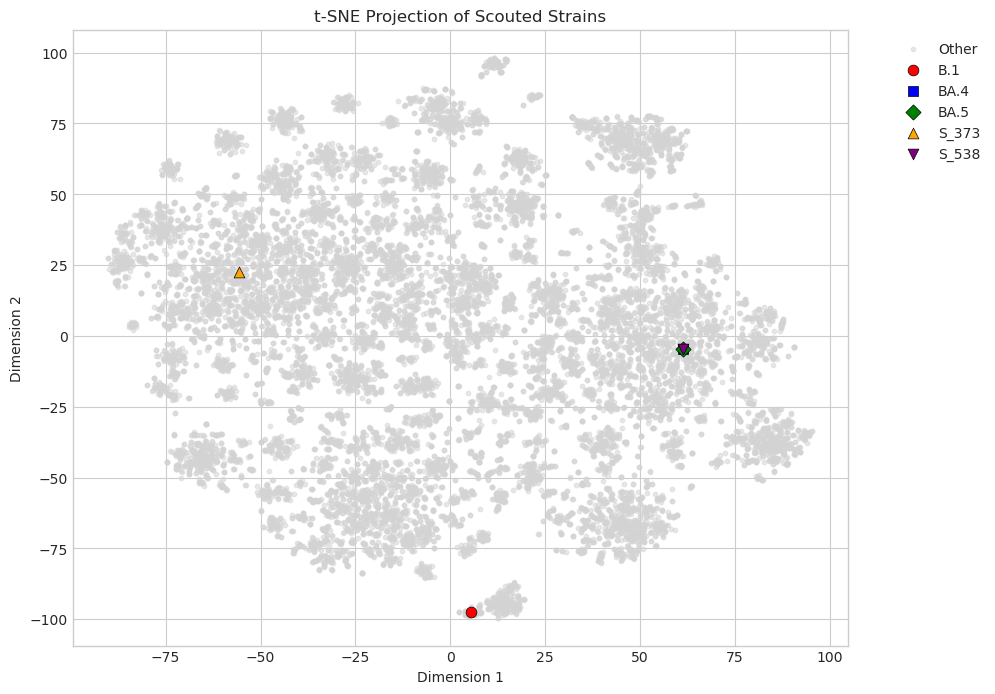

In [10]:
print("Running t-SNE...")
tsne_2d = get_projection(emb_all, method='tsne', random_state=0)
plot_projection(tsne_2d, names, method='tsne', title="t-SNE Projection of Scouted Strains")

Running UMAP...


/home/pgangwar@AD.UCSD.EDU/miniconda3/envs/ipynb-env/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


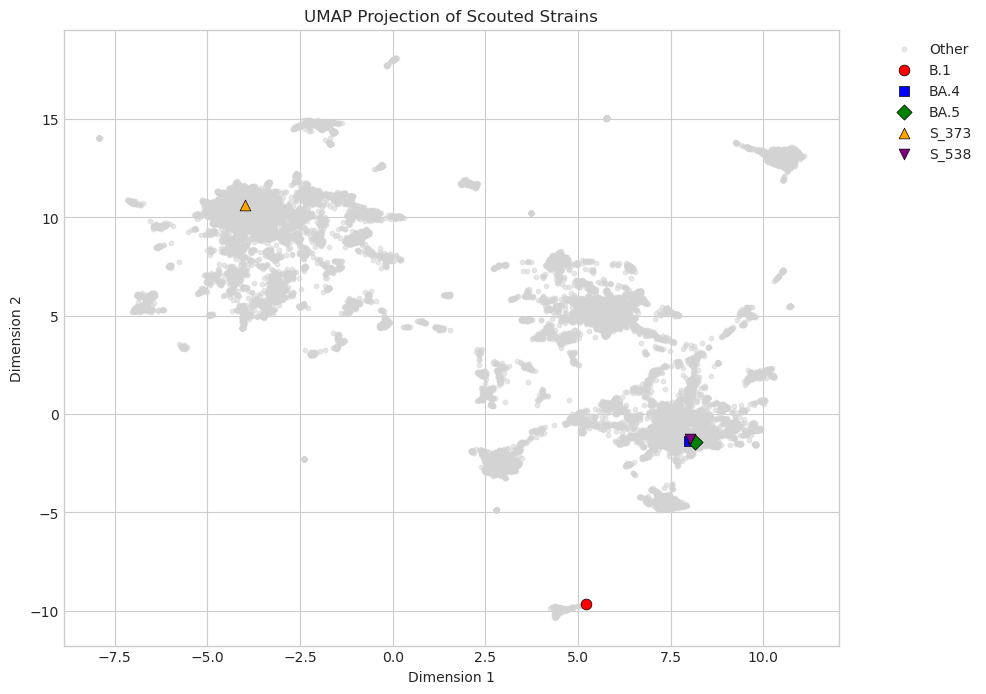

In [11]:
# Run UMAP
print("Running UMAP...")
umap_2d = get_projection(emb_all, method='umap', random_state=0)
plot_projection(umap_2d, names, method='umap', title="UMAP Projection of Scouted Strains")